# Maximum Likelihood Estimation and Model Selection for Stationary Renewable Energy Output Data
Guided walk-through. The heavy computations live in `src/` and are run by `main.py`; this notebook re-runs the key steps interactively and displays the saved results. Run `python main.py` first so that `results/` exists.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config, preprocessing as pp, stationarity as st, mle_models as mm, model_selection as ms
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Data: load, validate, aggregate

In [2]:
matrix = pp.load_raw_matrix()
index10 = pp.build_timestamps(len(matrix))
print(json.dumps(pp.validate_raw(matrix, index10), indent=1))
hourly = pp.to_hourly(pp.aggregate_fleet(matrix, index10))
frame = pp.build_analysis_frame(hourly)
print(pp.summarize_missing_and_unusual(frame))
frame.head(12)

{
 "n_rows": 52560,
 "n_plants": 137,
 "expected_rows": 52560,
 "rows_match_expected": true,
 "plants_match_expected": true,
 "n_missing": 0,
 "n_non_finite": 0,
 "n_negative": 0,
 "n_duplicate_timestamps": 0,
 "n_distinct_time_steps": 1,
 "time_step_minutes": 10.0,
 "n_plants_always_zero": 0,
 "plant_max_mw": 88.9,
 "first_timestamp": "2006-01-01 00:00:00",
 "last_timestamp": "2006-12-31 23:50:00"
}
{'n_hours': 8760, 'n_hours_exact_zero': 4076, 'share_hours_exact_zero': 0.46529680365296805, 'n_daylight_hours': 3848, 'n_daylight_zero_output': 2, 'n_in_sample': 3846, 'n_unusual_flagged': 15, 'n_index_above_1_20': 1, 'n_index_below_0_05': 14, 'n_index_above_1': 233, 'max_index': 1.2545650917300142, 'envelope_threshold_mw': 413.2328333333333}


,hourly_total_mw,envelope_mw,in_daylight,clearsky_index,in_sample,unusual,hour,day_of_year,month,day_index
2006-01-01 00:00:00,0.000000,0.000000,False,NaN,False,False,0,1,1,0
2006-01-01 01:00:00,0.000000,0.000000,False,NaN,False,False,1,1,1,0
2006-01-01 02:00:00,0.000000,0.000000,False,NaN,False,False,2,1,1,0
2006-01-01 03:00:00,0.000000,0.000000,False,NaN,False,False,3,1,1,0
2006-01-01 04:00:00,0.000000,0.000000,False,NaN,False,False,4,1,1,0
2006-01-01 05:00:00,0.000000,0.000000,False,NaN,False,False,5,1,1,0
2006-01-01 06:00:00,0.000000,0.000000,False,NaN,False,False,6,1,1,0
2006-01-01 07:00:00,197.833333,444.748333,True,0.444821,True,False,7,1,1,0
2006-01-01 08:00:00,813.958333,1741.346667,True,0.467430,True,False,8,1,1,0
2006-01-01 09:00:00,883.716667,2646.875000,True,0.333872,True,False,9,1,1,0


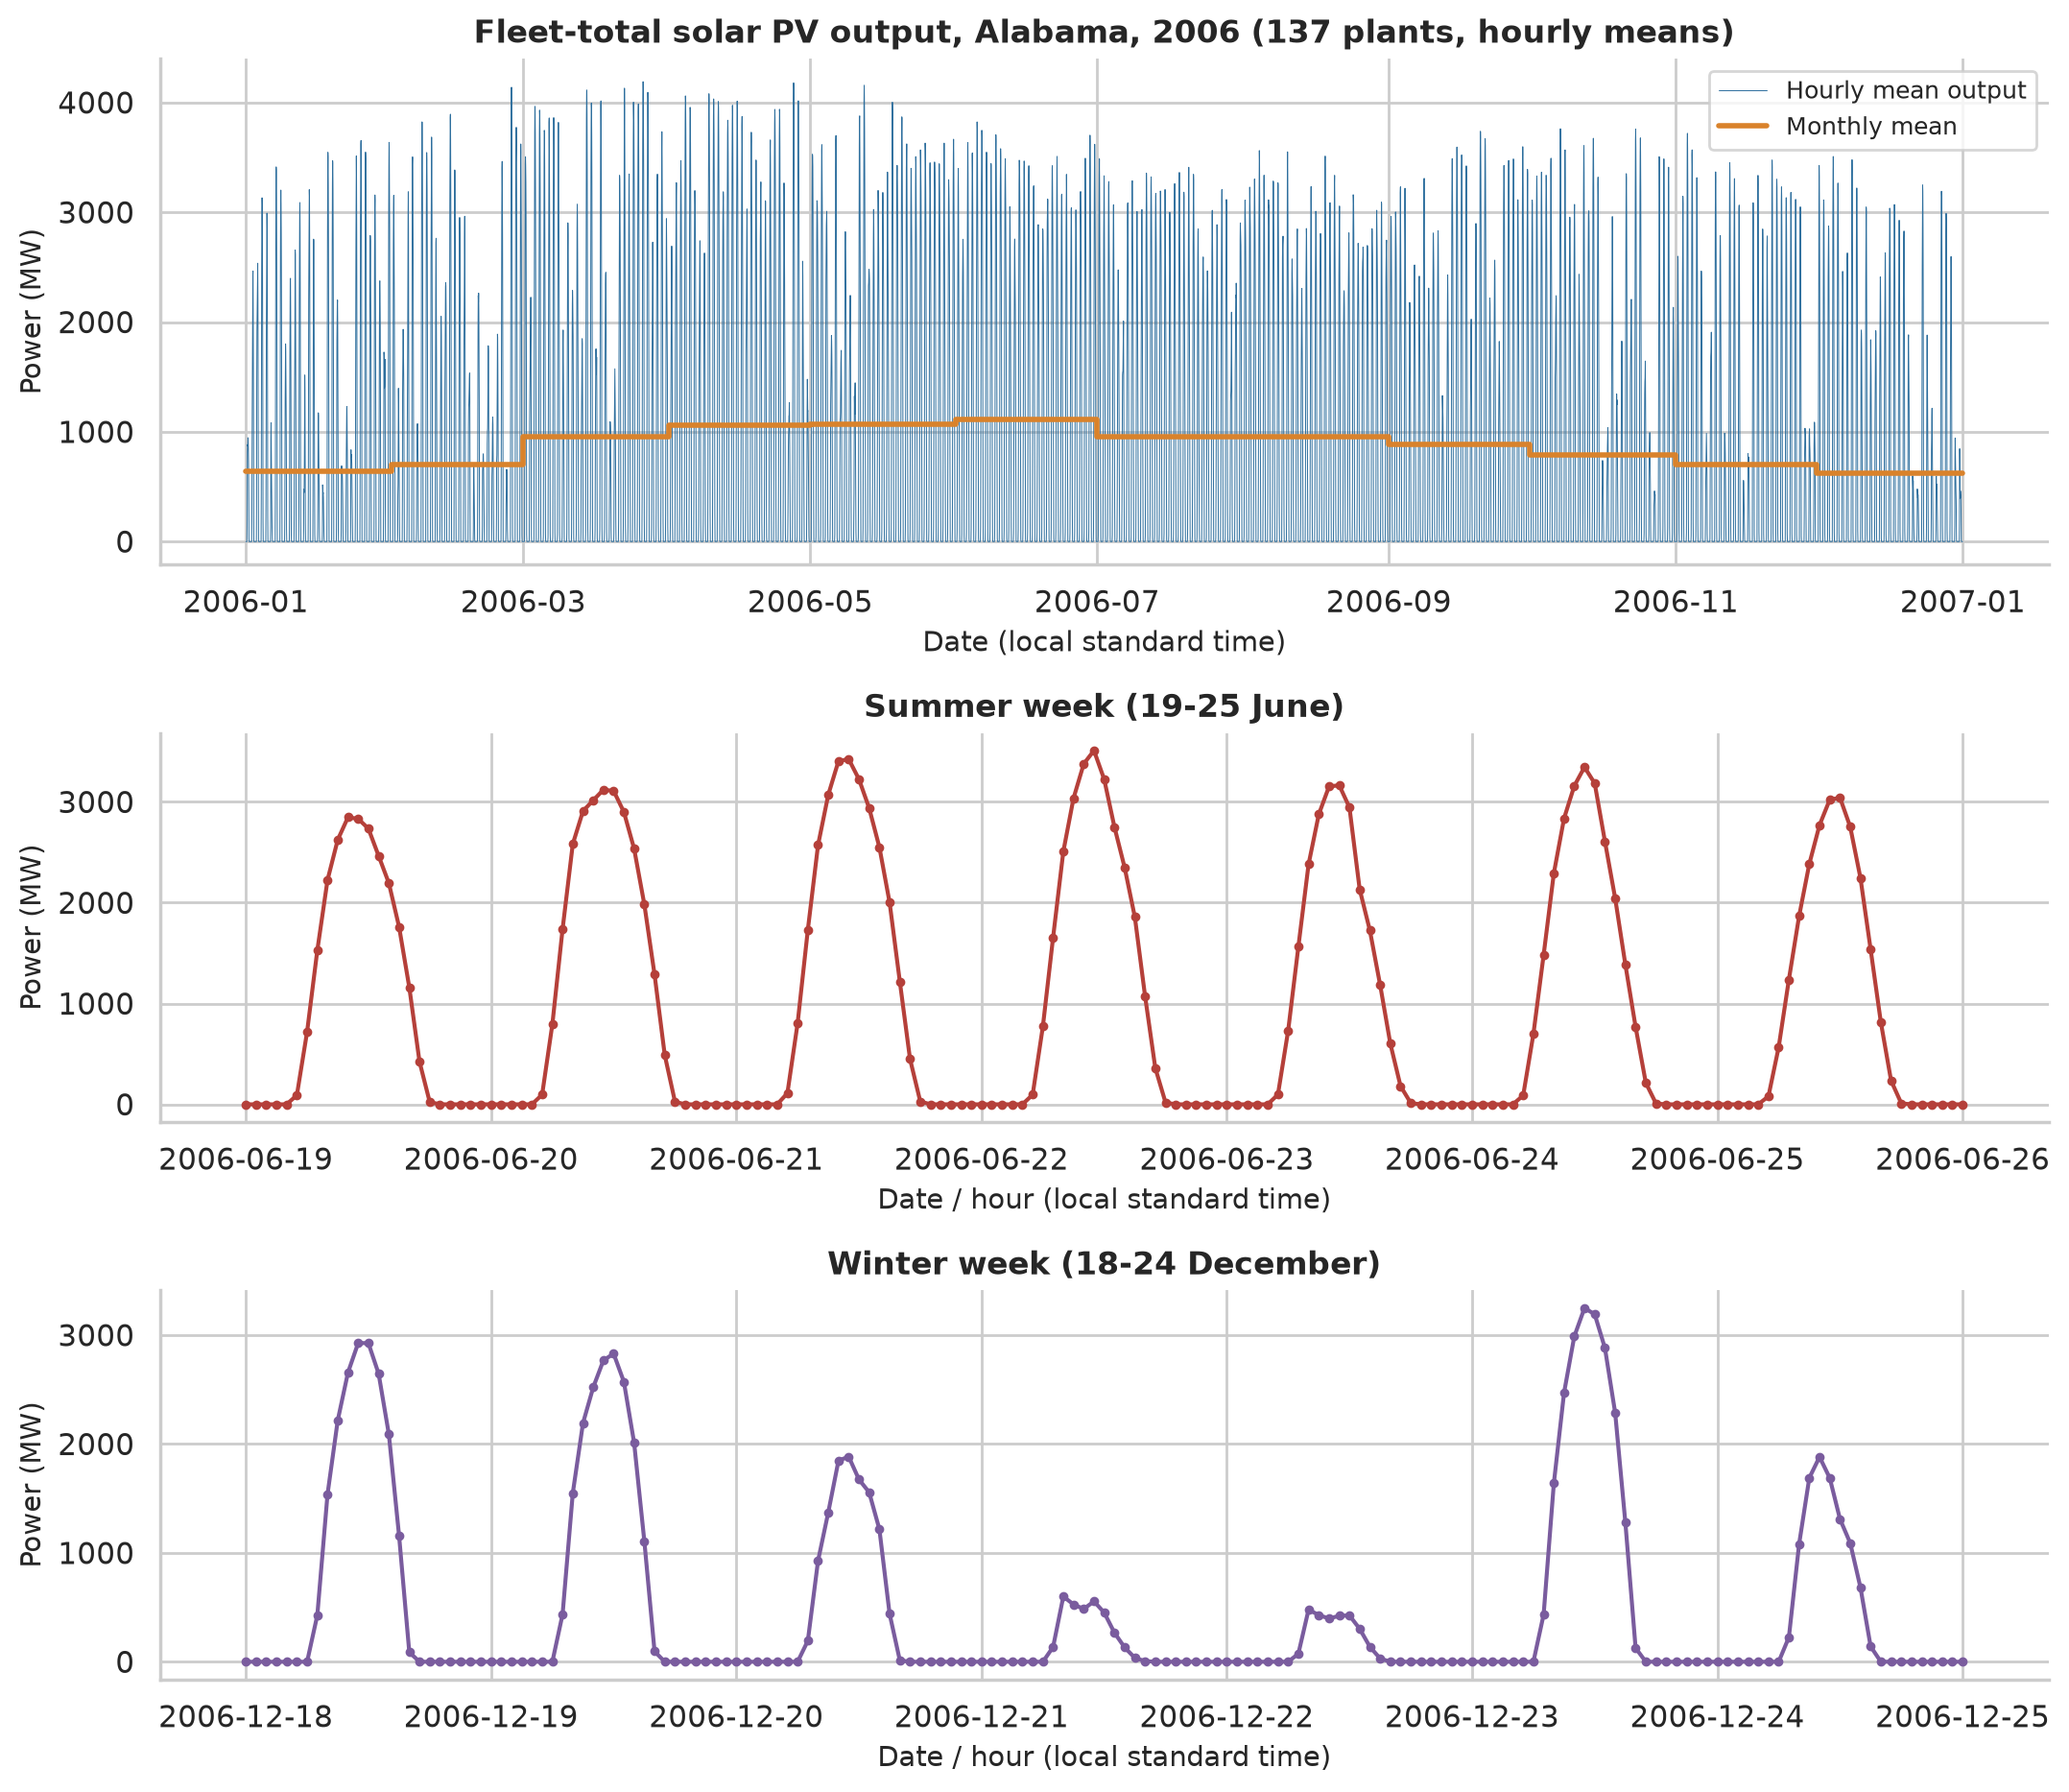

In [3]:
display(Image(str(config.FIG_DIR / 'fig01_hourly_series_overview.png')))

## 2. Zeros and the clear-sky index
Night-time zeros are structural, so the analysis series is the clear-sky index (output divided by an empirical clear-sky envelope) on daylight hours.

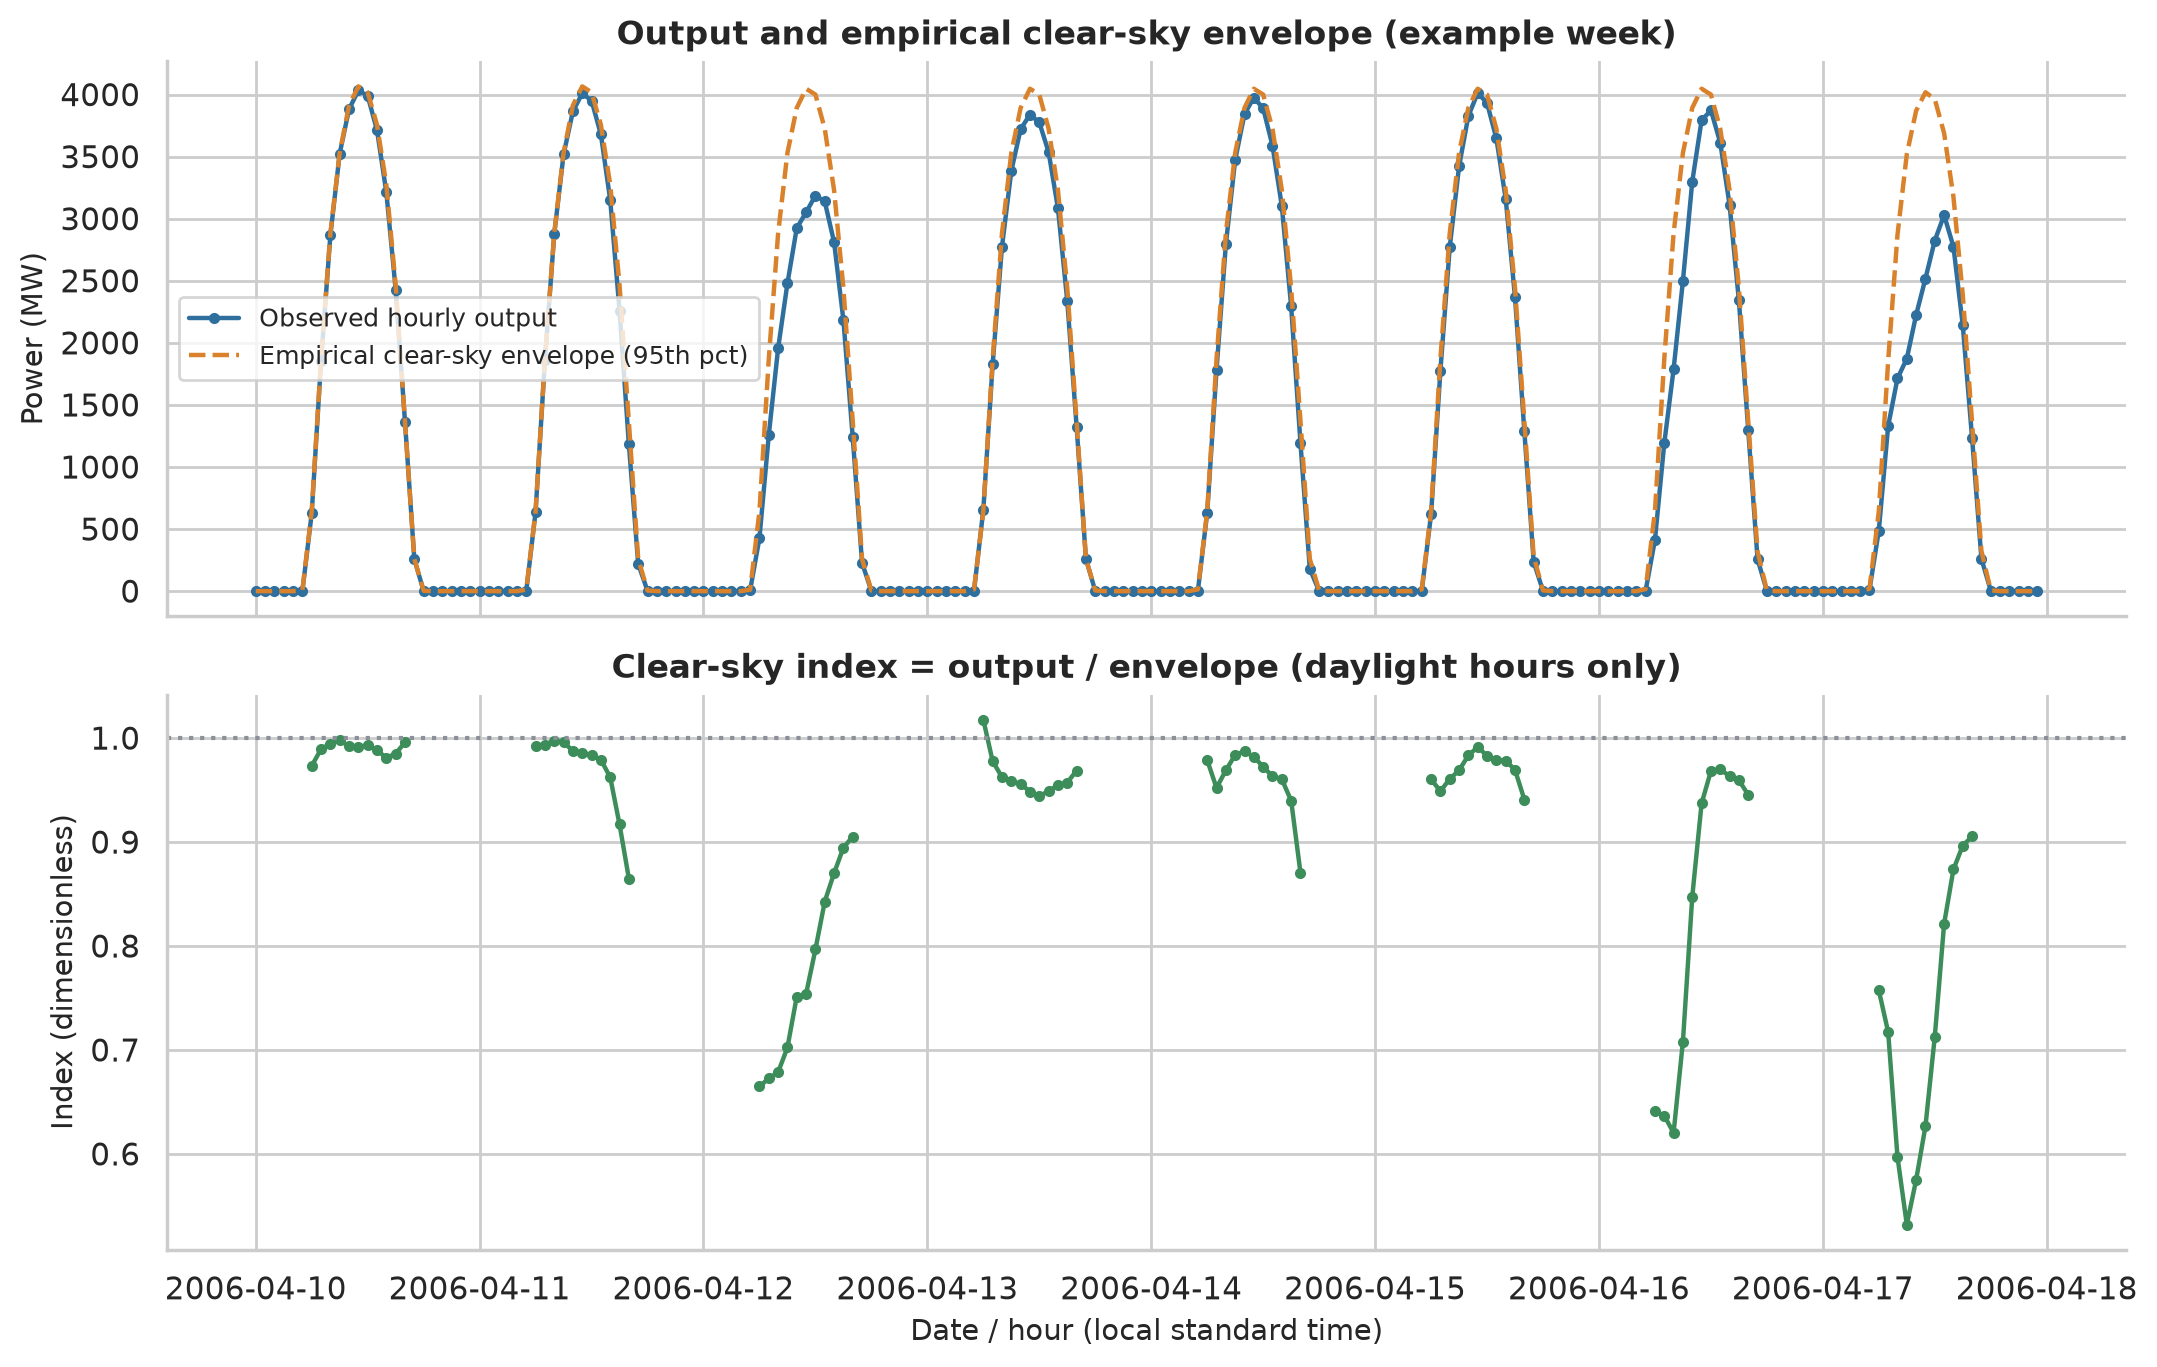

In [4]:
display(Image(str(config.FIG_DIR / 'fig04_clearsky_envelope_and_index.png')))

## 3. Stationarity

In [5]:
tests = pd.read_csv(config.RESULTS_DIR / 'stationarity_tests.csv')
tests[['series','test','specification','statistic','p_value','reject_H0','interpretation']]

,series,test,specification,statistic,p_value,reject_H0,interpretation
0,Raw hourly output (MW),ADF,"regression='c', lags by AIC",-10.673600,4.106850e-19,True,Reject H0: evidence against a unit root.
1,Raw hourly output (MW),KPSS,"regression='c', bandwidth=auto (data-driven)",2.470810,1.000000e-02,True,Reject H0: evidence against level stationarity.
2,Raw hourly output (MW),KPSS,"regression='c', bandwidth=37 (long rule)",1.673910,1.000000e-02,True,Reject H0: evidence against level stationarity.
3,Raw hourly output (MW),KPSS,"regression='ct', bandwidth=auto (data-driven)",1.961100,1.000000e-02,True,Reject H0: evidence against trend stationarity.
4,Raw daily mean output (MW),ADF,"regression='c', lags by AIC",-2.846980,5.187030e-02,False,Fail to reject H0: a unit root cannot be ruled...
5,Raw daily mean output (MW),KPSS,"regression='c', bandwidth=auto (data-driven)",0.822788,1.000000e-02,True,Reject H0: evidence against level stationarity.
6,Raw daily mean output (MW),KPSS,"regression='c', bandwidth=17 (long rule)",0.533990,3.401120e-02,True,Reject H0: evidence against level stationarity.
7,Raw daily mean output (MW),KPSS,"regression='ct', bandwidth=auto (data-driven)",0.670481,1.000000e-02,True,Reject H0: evidence against trend stationarity.
8,"Raw hourly, seasonal difference lag 24",ADF,"regression='c', lags by AIC",-19.076700,0.000000e+00,True,Reject H0: evidence against a unit root.
9,"Raw hourly, seasonal difference lag 24",KPSS,"regression='c', bandwidth=auto (data-driven)",0.023280,1.000000e-01,False,Fail to reject H0: consistent with level stati...


In [6]:
pd.read_csv(config.RESULTS_DIR / 'stationarity_verdicts.csv')

,series,adf_p,kpss_stat,kpss_p,verdict
0,Raw hourly output (MW),4.106850e-19,2.470810,0.010000,Conflicting: no unit root but not level-statio...
1,Raw daily mean output (MW),5.187030e-02,0.822788,0.010000,"Non-stationary (unit root not rejected, KPSS r..."
2,"Raw hourly, seasonal difference lag 24",0.000000e+00,0.023280,0.100000,"Stationary (ADF rejects unit root, KPSS does n..."
3,"Clear-sky index, daylight hours (concatenated)",4.586980e-23,0.830651,0.010000,Conflicting: no unit root but not level-statio...
4,Clear-sky index at 12:00 (daily),3.983140e-08,0.600284,0.022610,Conflicting: no unit root but not level-statio...
5,Daily mean clear-sky index,3.072670e-10,0.615372,0.021239,Conflicting: no unit root but not level-statio...
6,Clear-sky index minus annual harmonic,2.090840e-25,0.026185,0.100000,"Stationary (ADF rejects unit root, KPSS does n..."


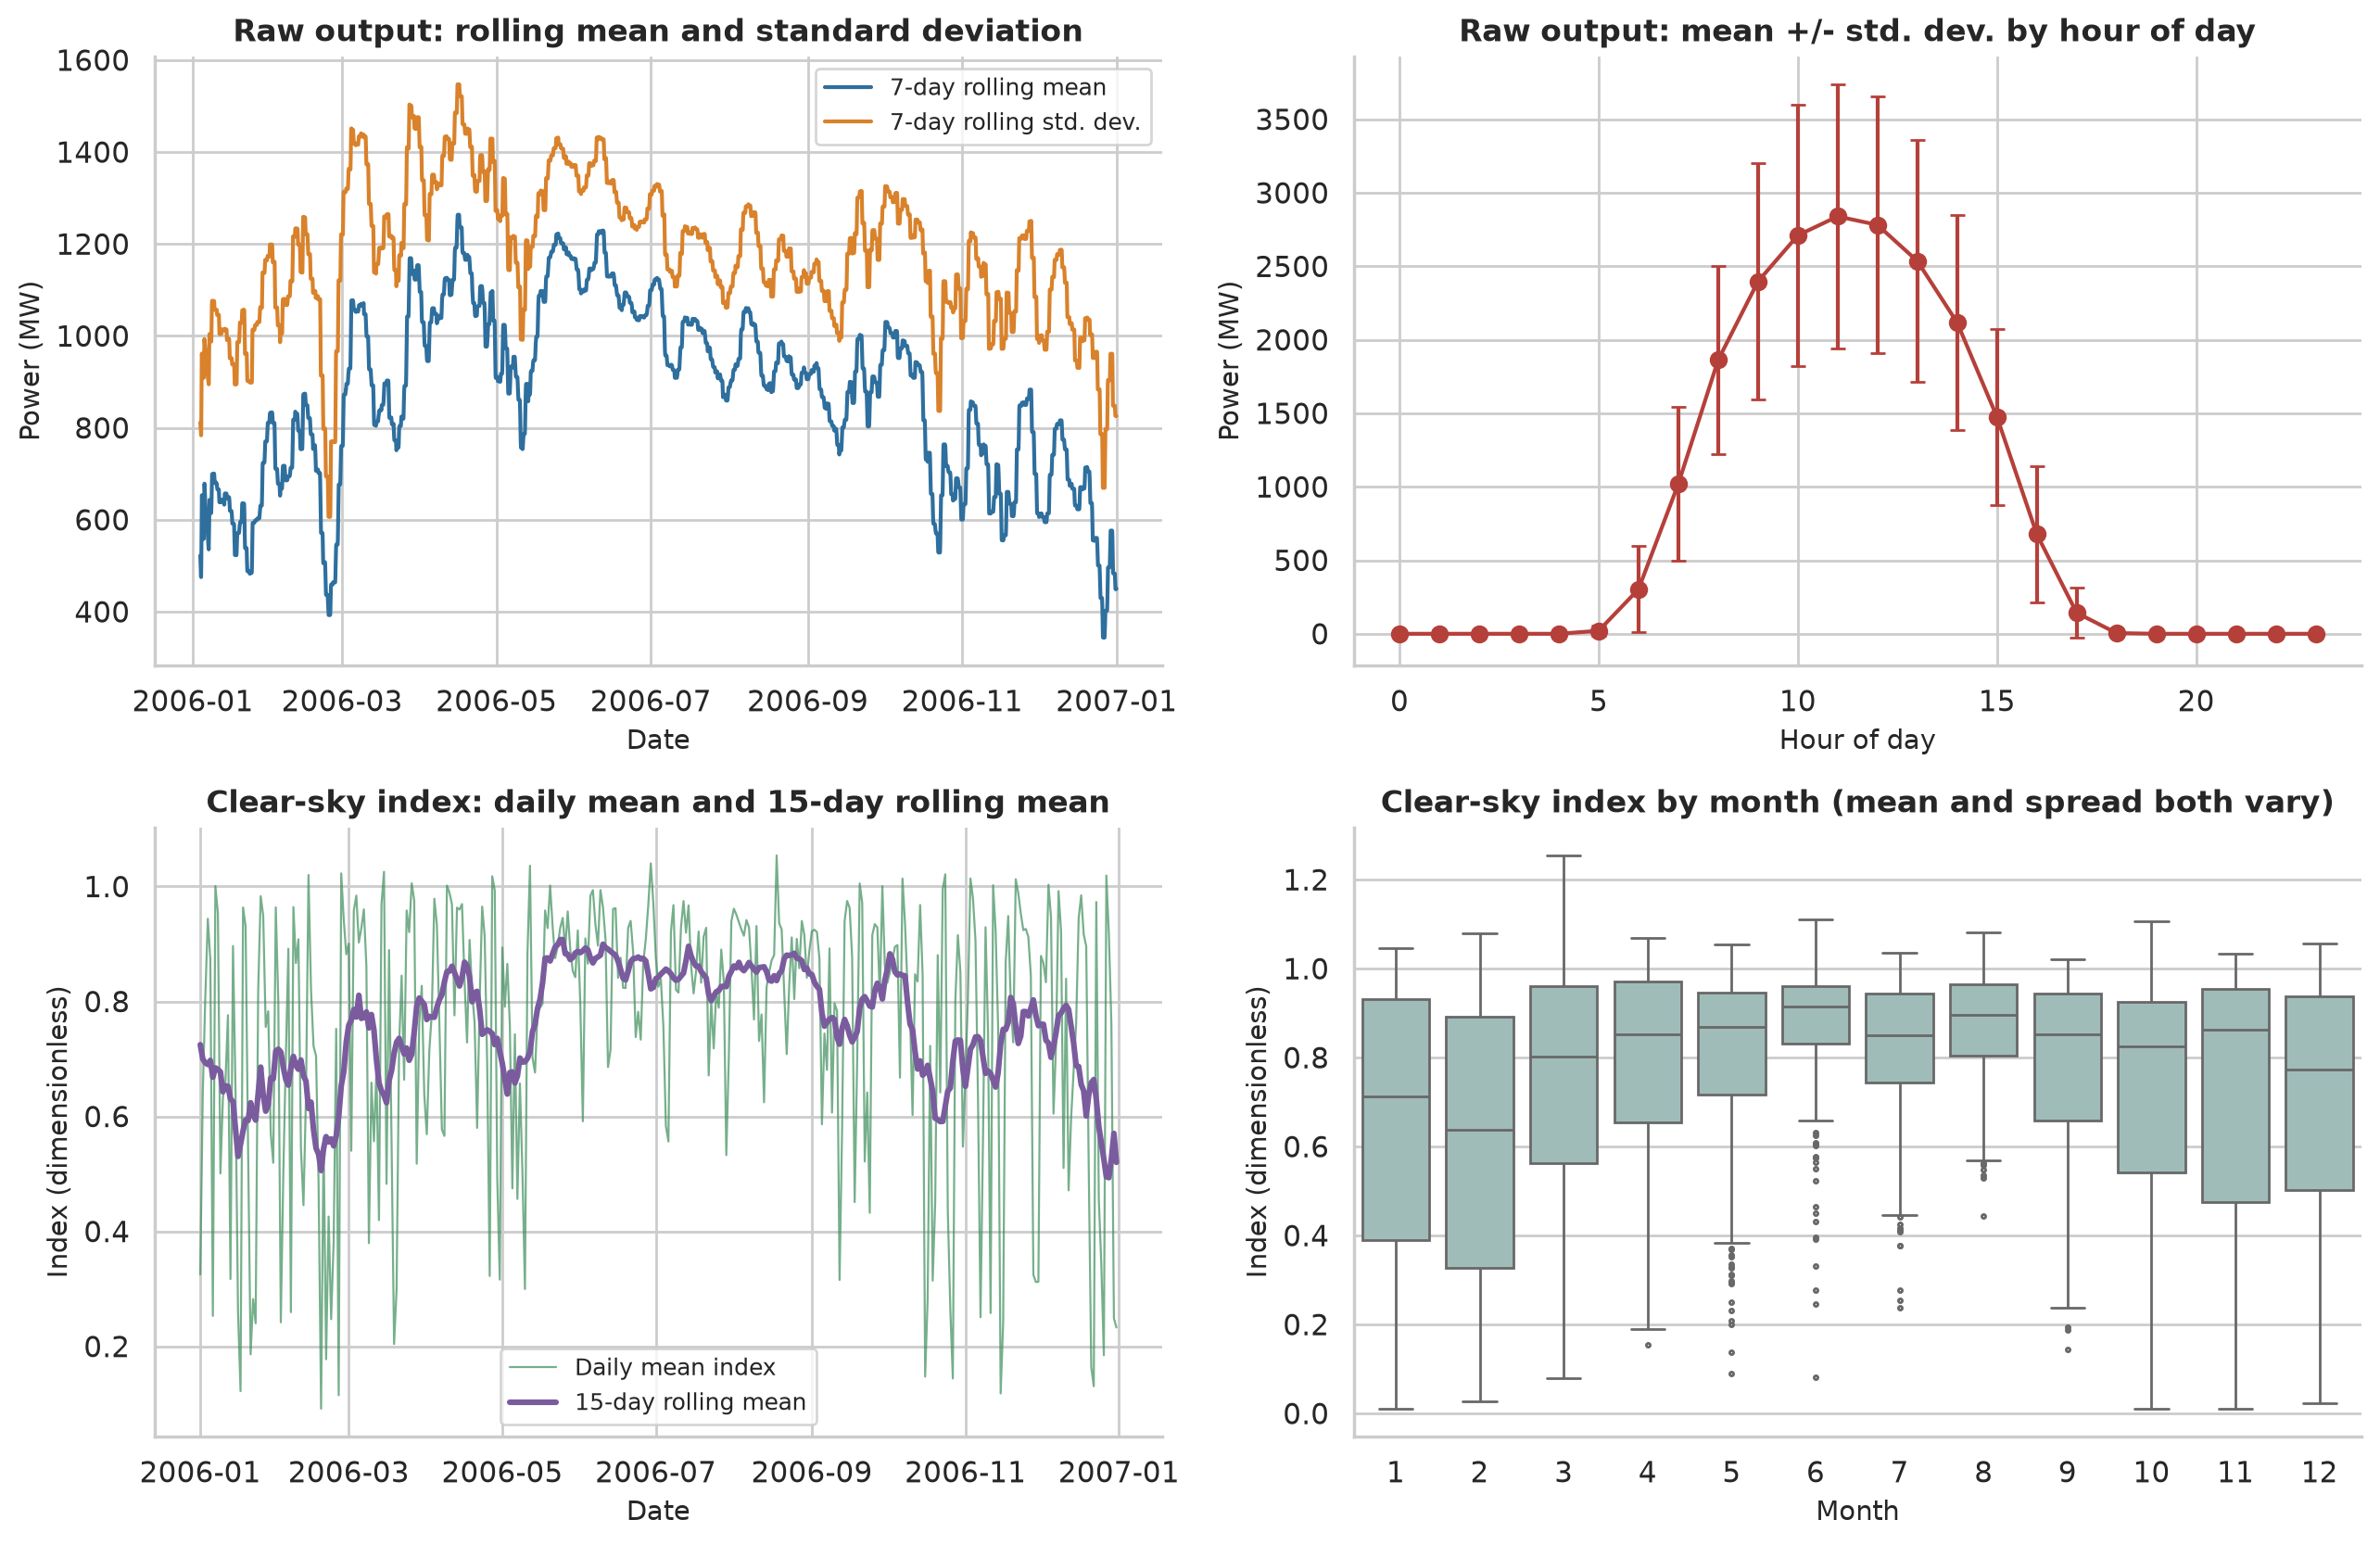

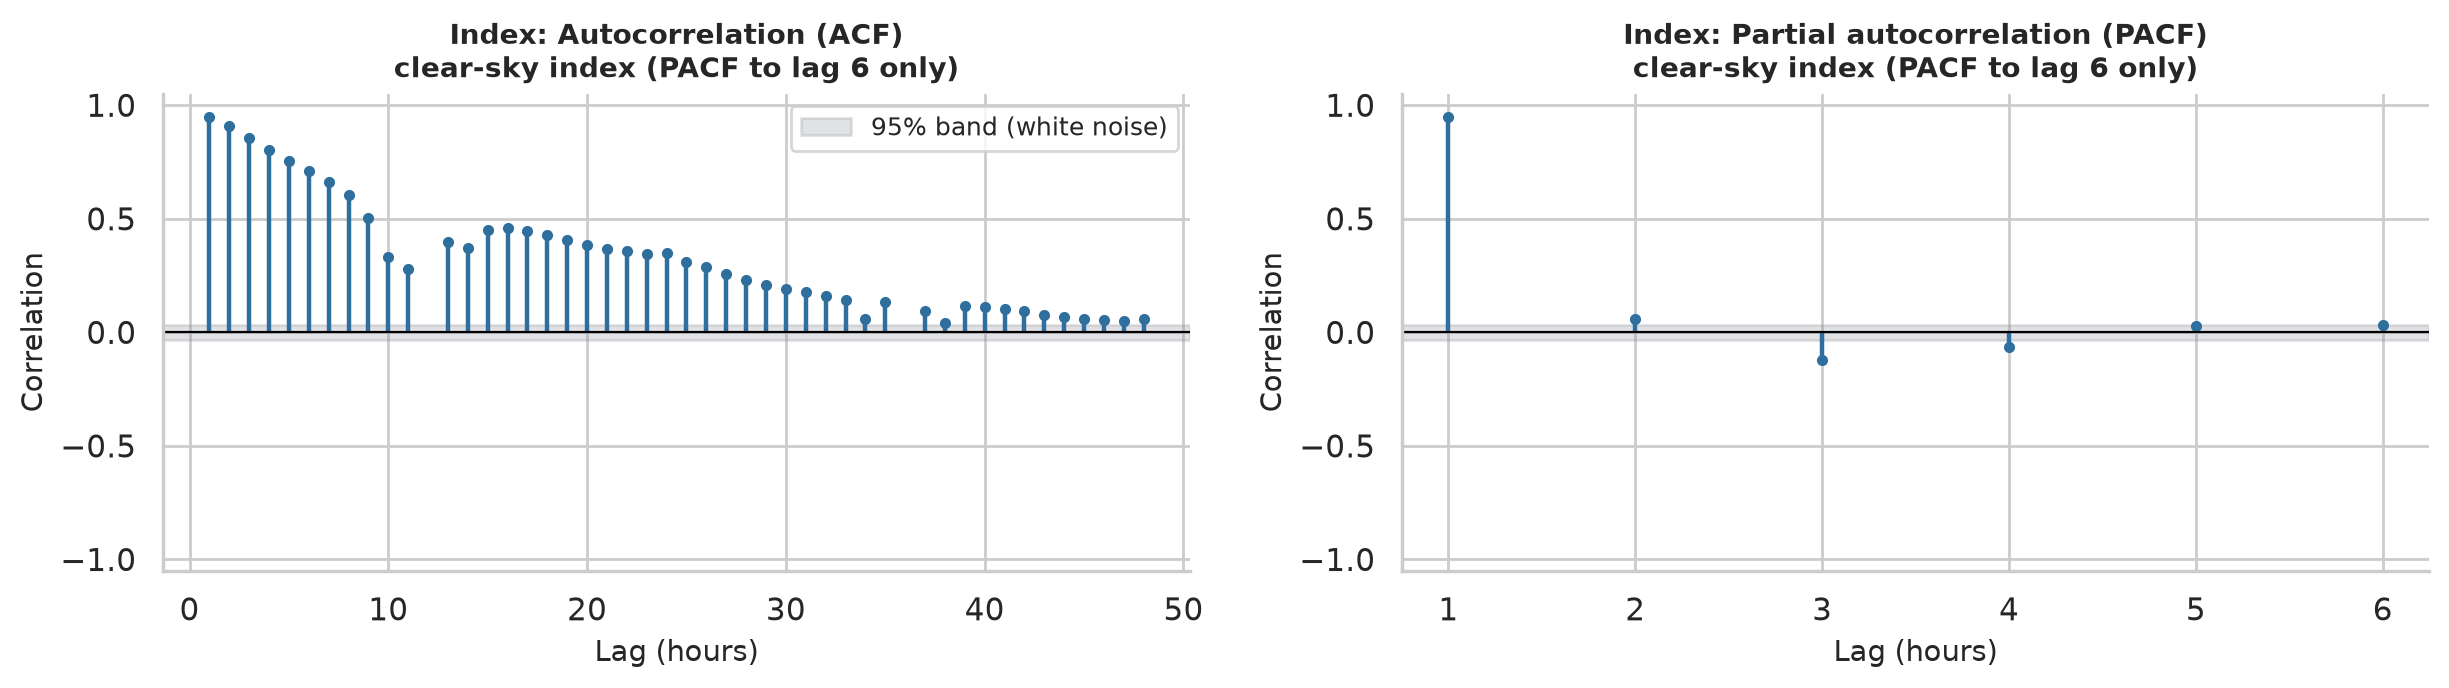

In [7]:
display(Image(str(config.FIG_DIR / 'fig05_rolling_statistics_and_group_effects.png')))
display(Image(str(config.FIG_DIR / 'fig06b_acf_pacf_clearsky_index.png')))

## 4. Maximum likelihood estimation
A minimal demonstration with the Weibull model: maximise the log-likelihood numerically and compare with SciPy.

In [8]:
x = frame.loc[frame['in_sample'], 'clearsky_index'].to_numpy()
weibull = mm.Weibull()
fit = weibull.fit(x)
print(fit.params, fit.loglik, fit.converged)
print(mm.validate_against_scipy(x, weibull, fit))

{'shape': 3.8502063276330274, 'scale': 0.8416354298249801} -22.06940509829809 True
{'model': 'Weibull', 'our_loglik': -22.06940509829809, 'scipy_loglik': -22.069405507743397, 'loglik_difference_ours_minus_scipy': 4.0944530610431684e-07, 'max_abs_param_difference': 4.528117677882193e-05, 'max_rel_param_difference': 1.1760576029684276e-05, 'validated': True}


In [9]:
pd.read_csv(config.RESULTS_DIR / 'mle_estimates.csv')

,model,parameter,estimate,std_error,ci95_low,ci95_high,loglik,n
0,Normal,mu,0.763780,0.003893,0.756150,0.771410,8.79304,3846
1,Normal,sigma,0.241418,0.002753,0.236023,0.246813,8.79304,3846
2,Student-t,mu,0.812815,0.005818,0.801412,0.824218,45.12700,3846
3,Student-t,sigma,0.188409,0.005830,0.176982,0.199835,45.12700,3846
4,Student-t,nu,4.393030,0.526213,3.361650,5.424410,45.12700,3846
5,Log-normal,mu_log,-0.357052,0.008087,-0.372903,-0.341202,-1429.94000,3846
6,Log-normal,sigma_log,0.501533,0.005718,0.490324,0.512741,-1429.94000,3846
7,Gamma,shape,5.870920,0.130253,5.615630,6.126220,-789.25500,3846
8,Gamma,scale,0.130095,0.003013,0.124189,0.136001,-789.25500,3846
9,Weibull,shape,3.850210,0.055174,3.742070,3.958350,-22.06940,3846


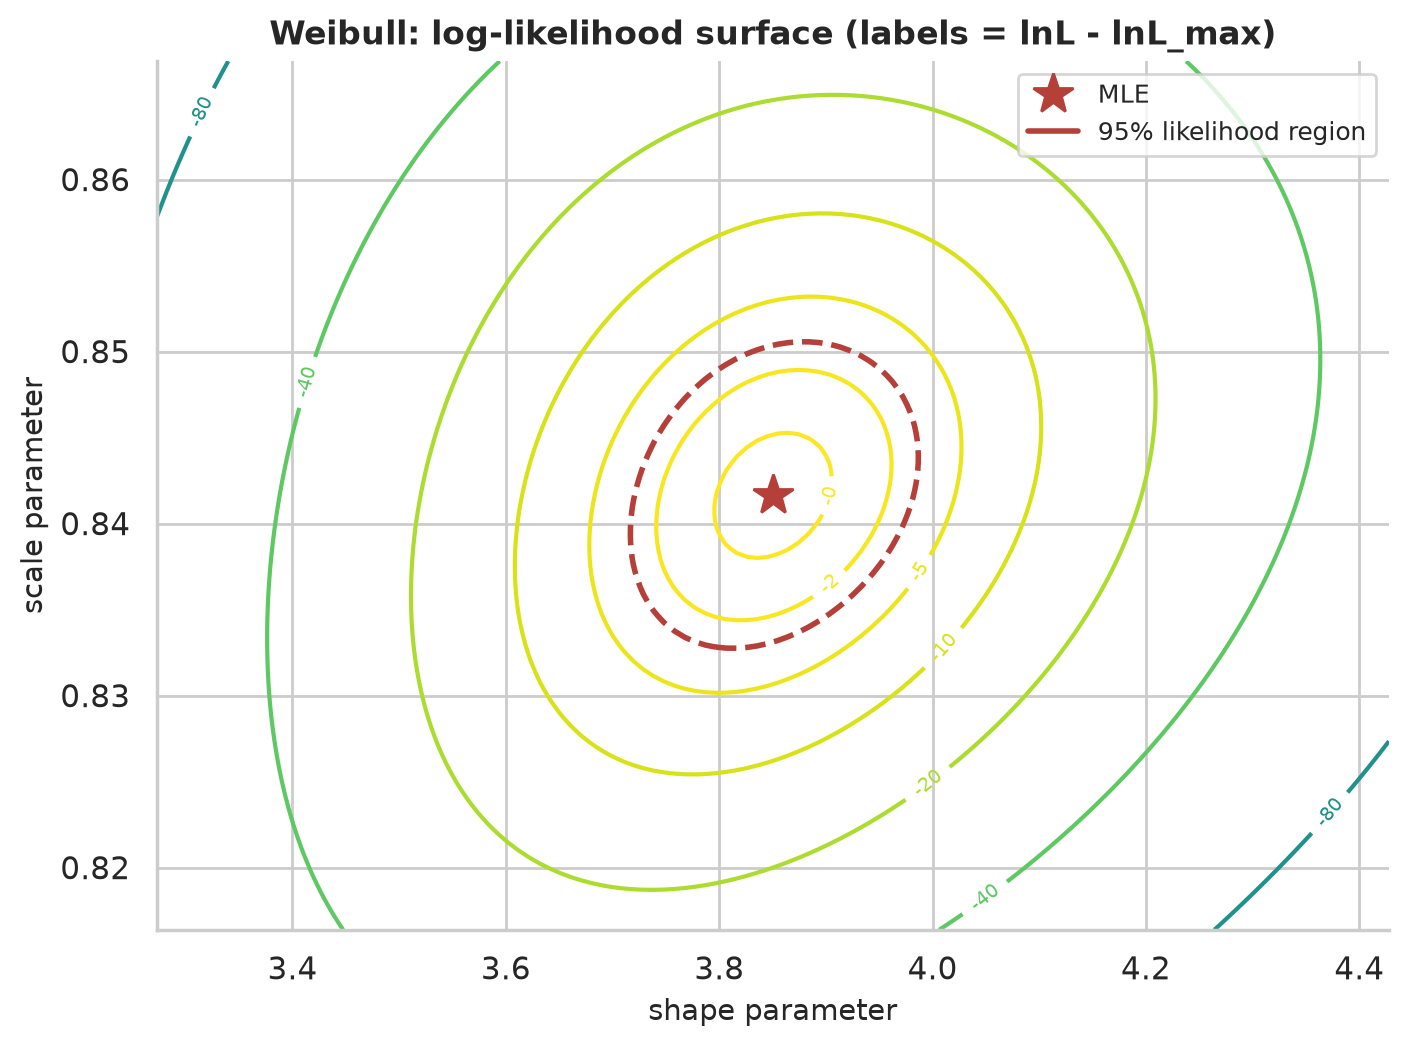

In [10]:
display(Image(str(config.FIG_DIR / 'fig07_likelihood_surface_weibull.png')))

## 5. Model selection (AIC / BIC / goodness of fit)

In [11]:
pd.read_csv(config.RESULTS_DIR / 'model_comparison.csv')[['model','k','loglik','AIC','BIC','delta_AIC','delta_BIC','weight_BIC','KS_statistic','KS_p_bootstrap','AD_p_bootstrap']]

,model,k,loglik,AIC,BIC,delta_AIC,delta_BIC,weight_BIC,KS_statistic,KS_p_bootstrap,AD_p_bootstrap
0,2-component normal mixture,5,1001.05000,-1992.1000,-1960.83000,0.00,0.00,1,0.036444,0.004975,0.004975
1,Beta (scaled),2,91.95940,-179.9190,-167.40900,1812.18,1793.42,0,0.146453,0.004975,0.004975
2,Student-t,3,45.12700,-84.2541,-65.48970,1907.85,1895.34,0,0.142487,0.004975,0.004975
3,Normal,2,8.79304,-13.5861,-1.07651,1978.52,1959.75,0,0.143025,0.004975,0.004975
4,Weibull,2,-22.06940,48.1388,60.64840,2040.24,2021.48,0,0.146126,0.004975,0.004975
5,Gamma,2,-789.25500,1582.5100,1595.02000,3574.61,3555.85,0,0.184510,0.004975,0.004975
6,Log-normal,2,-1429.94000,2863.8800,2876.39000,4855.98,4837.22,0,0.206796,0.004975,0.004975


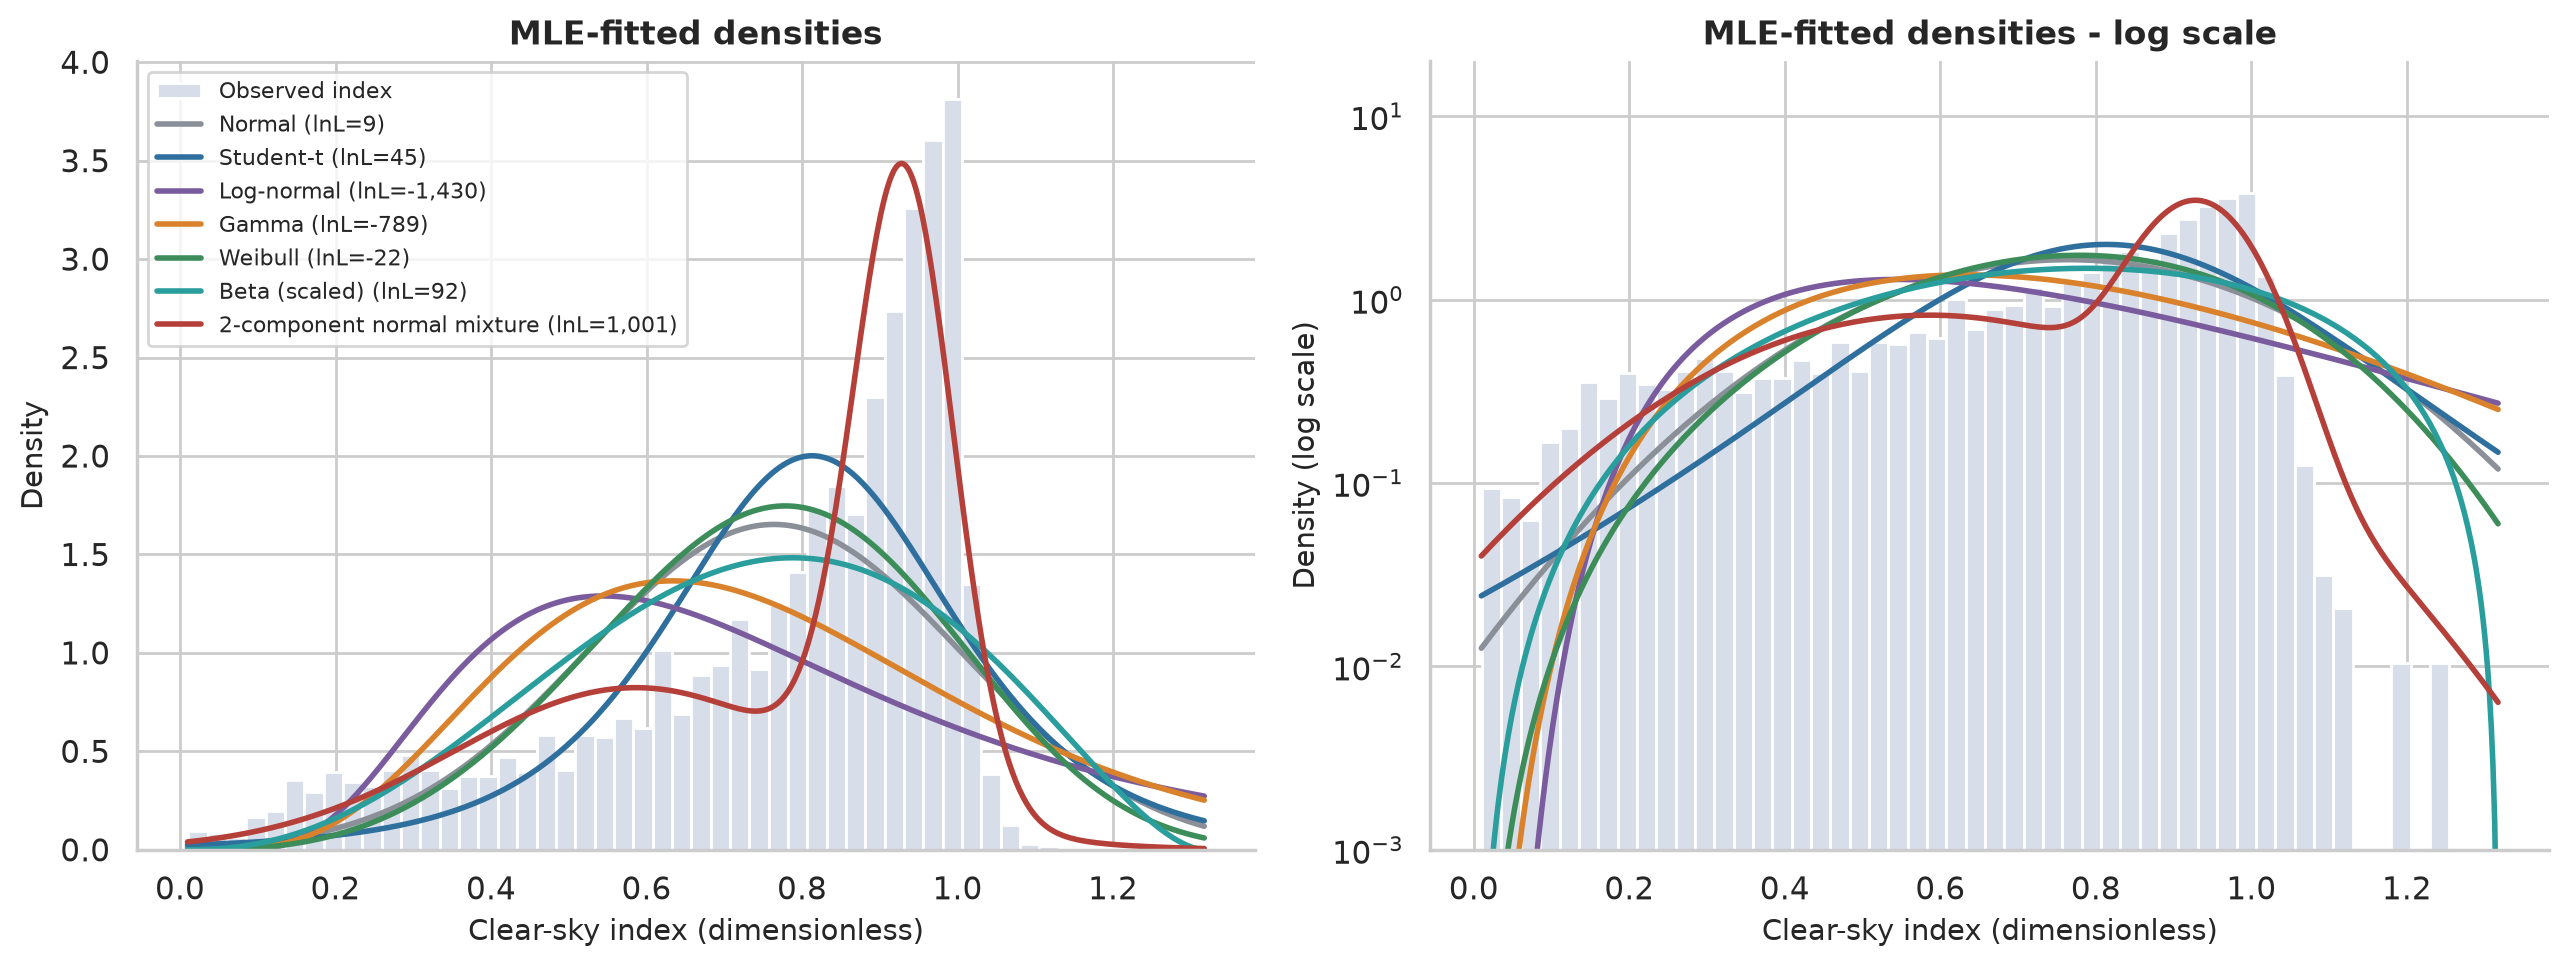

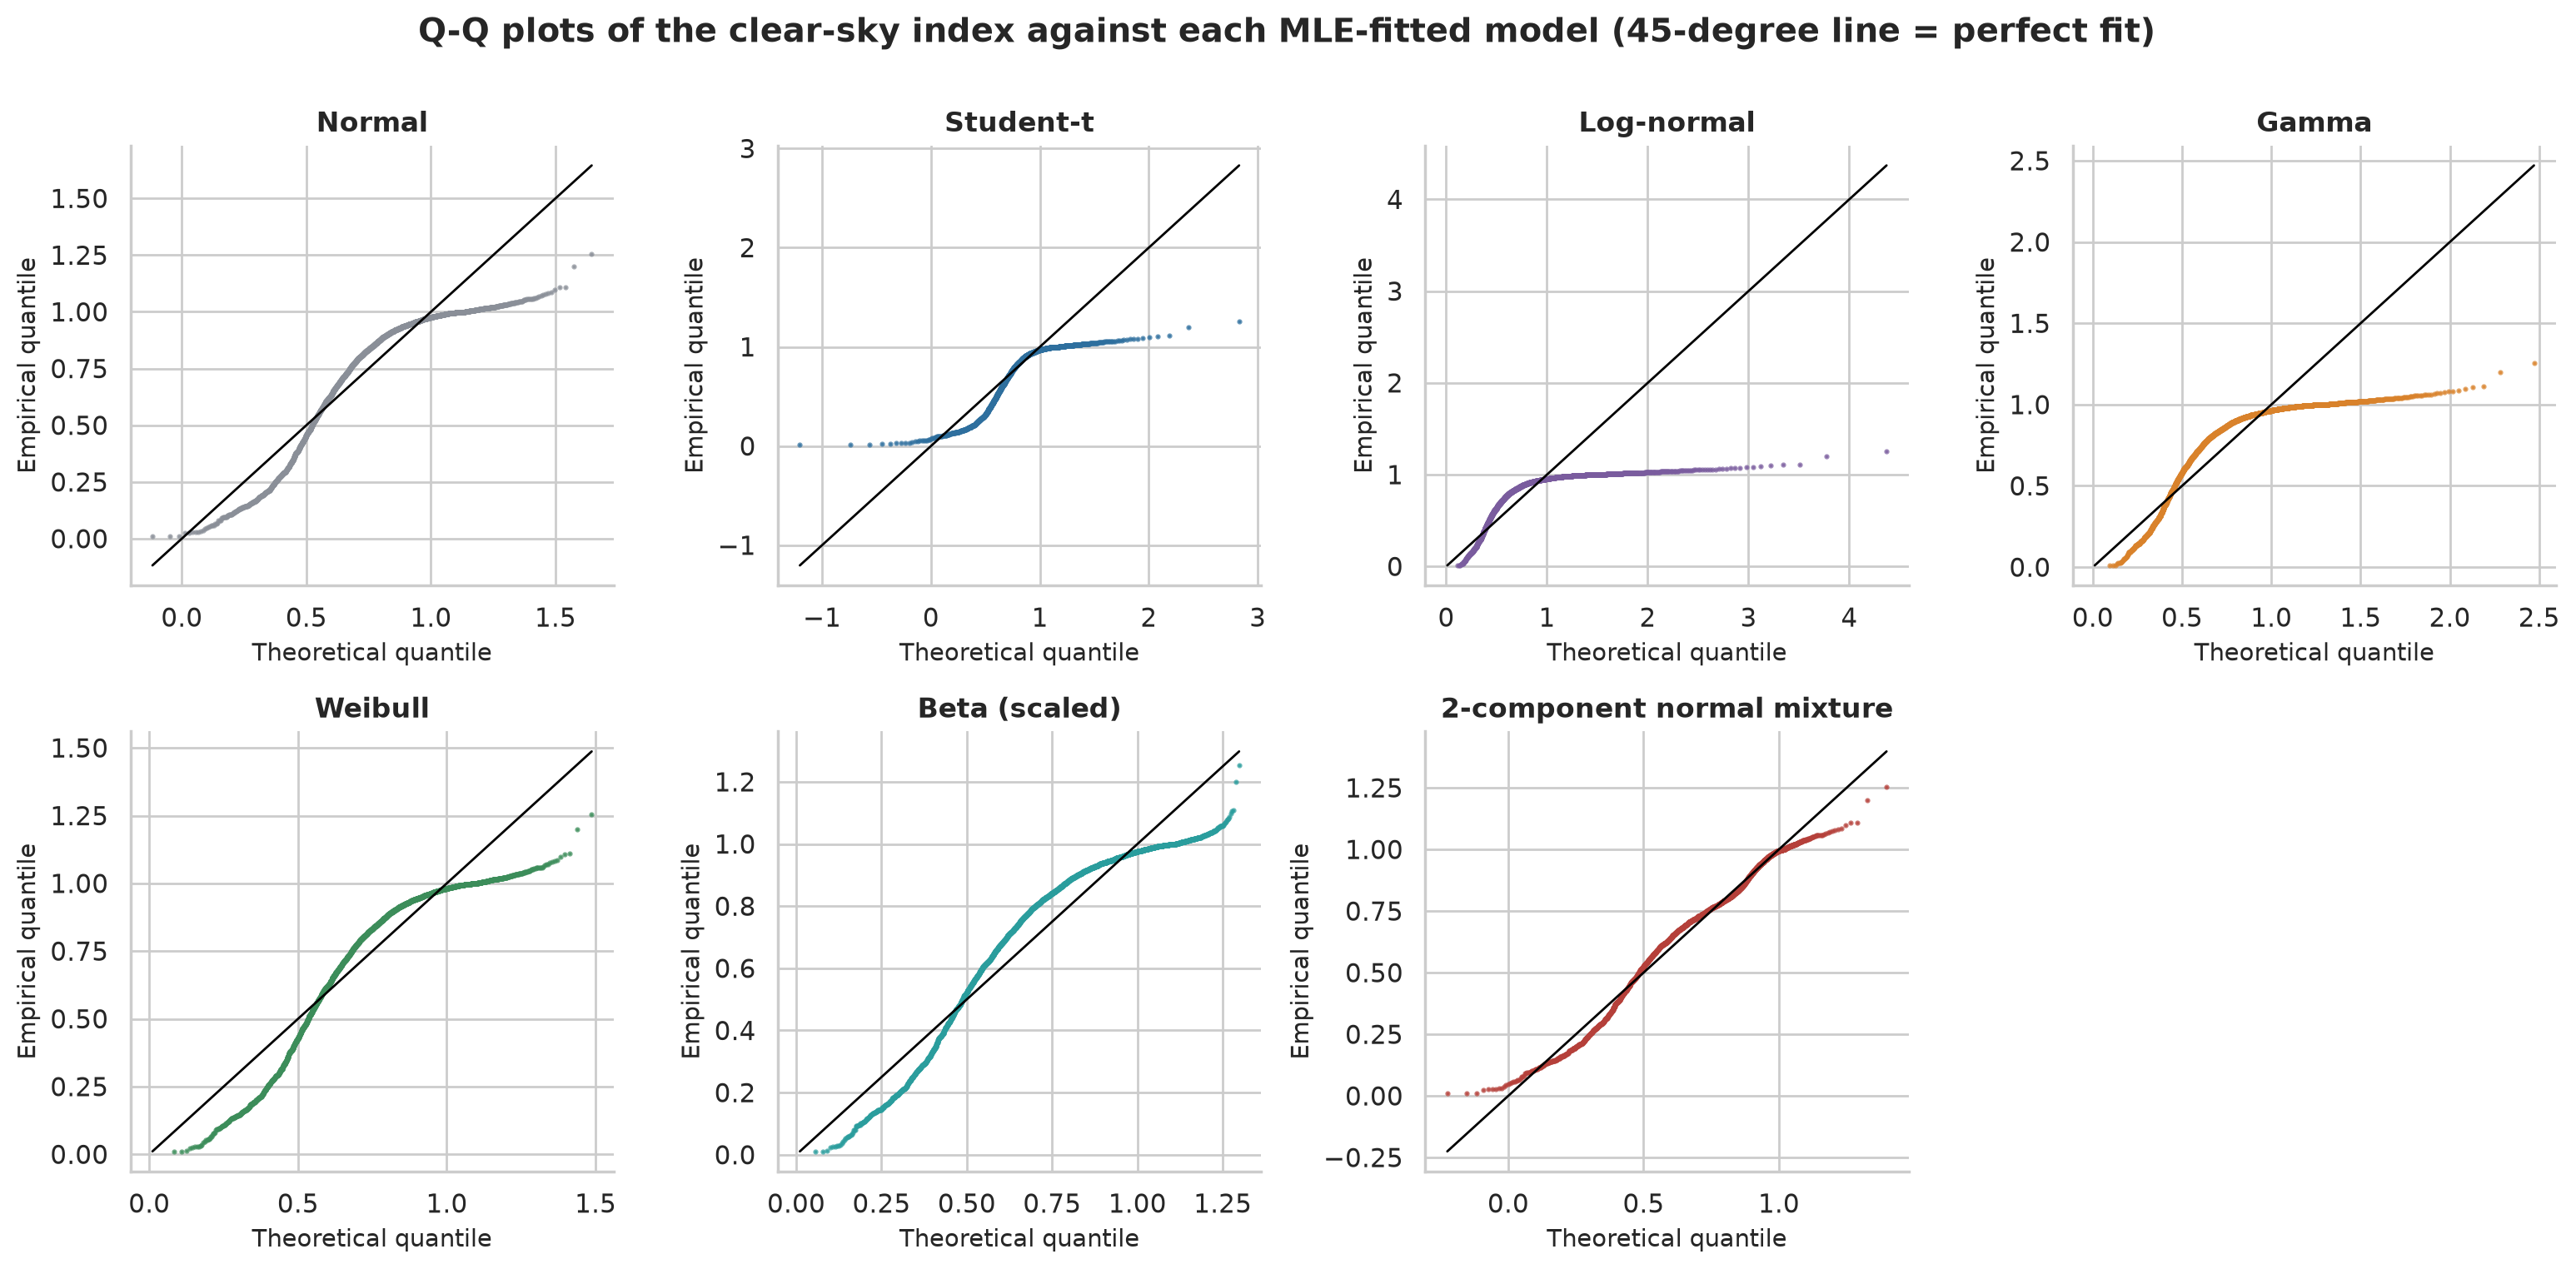

In [12]:
display(Image(str(config.FIG_DIR / 'fig08_fitted_densities.png')))
display(Image(str(config.FIG_DIR / 'fig09_qq_plots.png')))

## 6. Time-series models and diagnostics

In [13]:
pd.read_csv(config.RESULTS_DIR / 'timeseries_model_comparison.csv')[['model','k','loglik','AIC','BIC','delta_BIC','converged']]

,model,k,loglik,AIC,BIC,delta_BIC,converged
0,"ARMA(2,1)x(1,0,0)24, no annual cycle",6,6216.430,-12420.900,-12383.300,0.00000,True
1,"ARMA(2,1)x(1,0,0)24",8,6221.680,-12427.400,-12377.300,6.01124,True
2,"ARMA(1,1)x(1,0,0)24",7,6118.980,-12224.000,-12180.200,203.16400,True
3,"ARMA(2,1)",7,5878.030,-11742.100,-11698.300,685.05000,True
4,"ARMA(2,2)",8,5881.110,-11746.200,-11696.200,687.16200,True
5,AR(3),7,5869.520,-11725.000,-11681.300,702.08500,True
6,AR(2),6,5849.850,-11687.700,-11650.200,733.16200,True
7,"ARMA(1,1)",6,5821.800,-11631.600,-11594.100,789.26100,True
8,AR(1),5,5346.550,-10683.100,-10651.800,1731.51000,True
9,iid Gaussian + annual cycle,4,210.638,-413.276,-388.256,11995.10000,True


In [14]:
pd.read_csv(config.RESULTS_DIR / 'model_comparison_all_families.csv')

,model,k,n,loglik,AIC,BIC,family,delta_BIC
0,"ARMA(2,1)x(1,0,0)24, no annual cycle",6,3846,6216.43000,-12420.9000,-12383.30000,ARMA-type (time order used),0.00000
1,"ARMA(2,1)x(1,0,0)24",8,3846,6221.68000,-12427.4000,-12377.30000,ARMA-type (time order used),6.01124
2,"ARMA(1,1)x(1,0,0)24",7,3846,6118.98000,-12224.0000,-12180.20000,ARMA-type (time order used),203.16400
3,"ARMA(2,1)",7,3846,5878.03000,-11742.1000,-11698.30000,ARMA-type (time order used),685.05000
4,"ARMA(2,2)",8,3846,5881.11000,-11746.2000,-11696.20000,ARMA-type (time order used),687.16200
5,AR(3),7,3846,5869.52000,-11725.0000,-11681.30000,ARMA-type (time order used),702.08500
6,AR(2),6,3846,5849.85000,-11687.7000,-11650.20000,ARMA-type (time order used),733.16200
7,"ARMA(1,1)",6,3846,5821.80000,-11631.6000,-11594.10000,ARMA-type (time order used),789.26100
8,AR(1),5,3846,5346.55000,-10683.1000,-10651.80000,ARMA-type (time order used),1731.51000
9,2-component normal mixture,5,3846,1001.05000,-1992.1000,-1960.83000,i.i.d. distribution,10422.50000


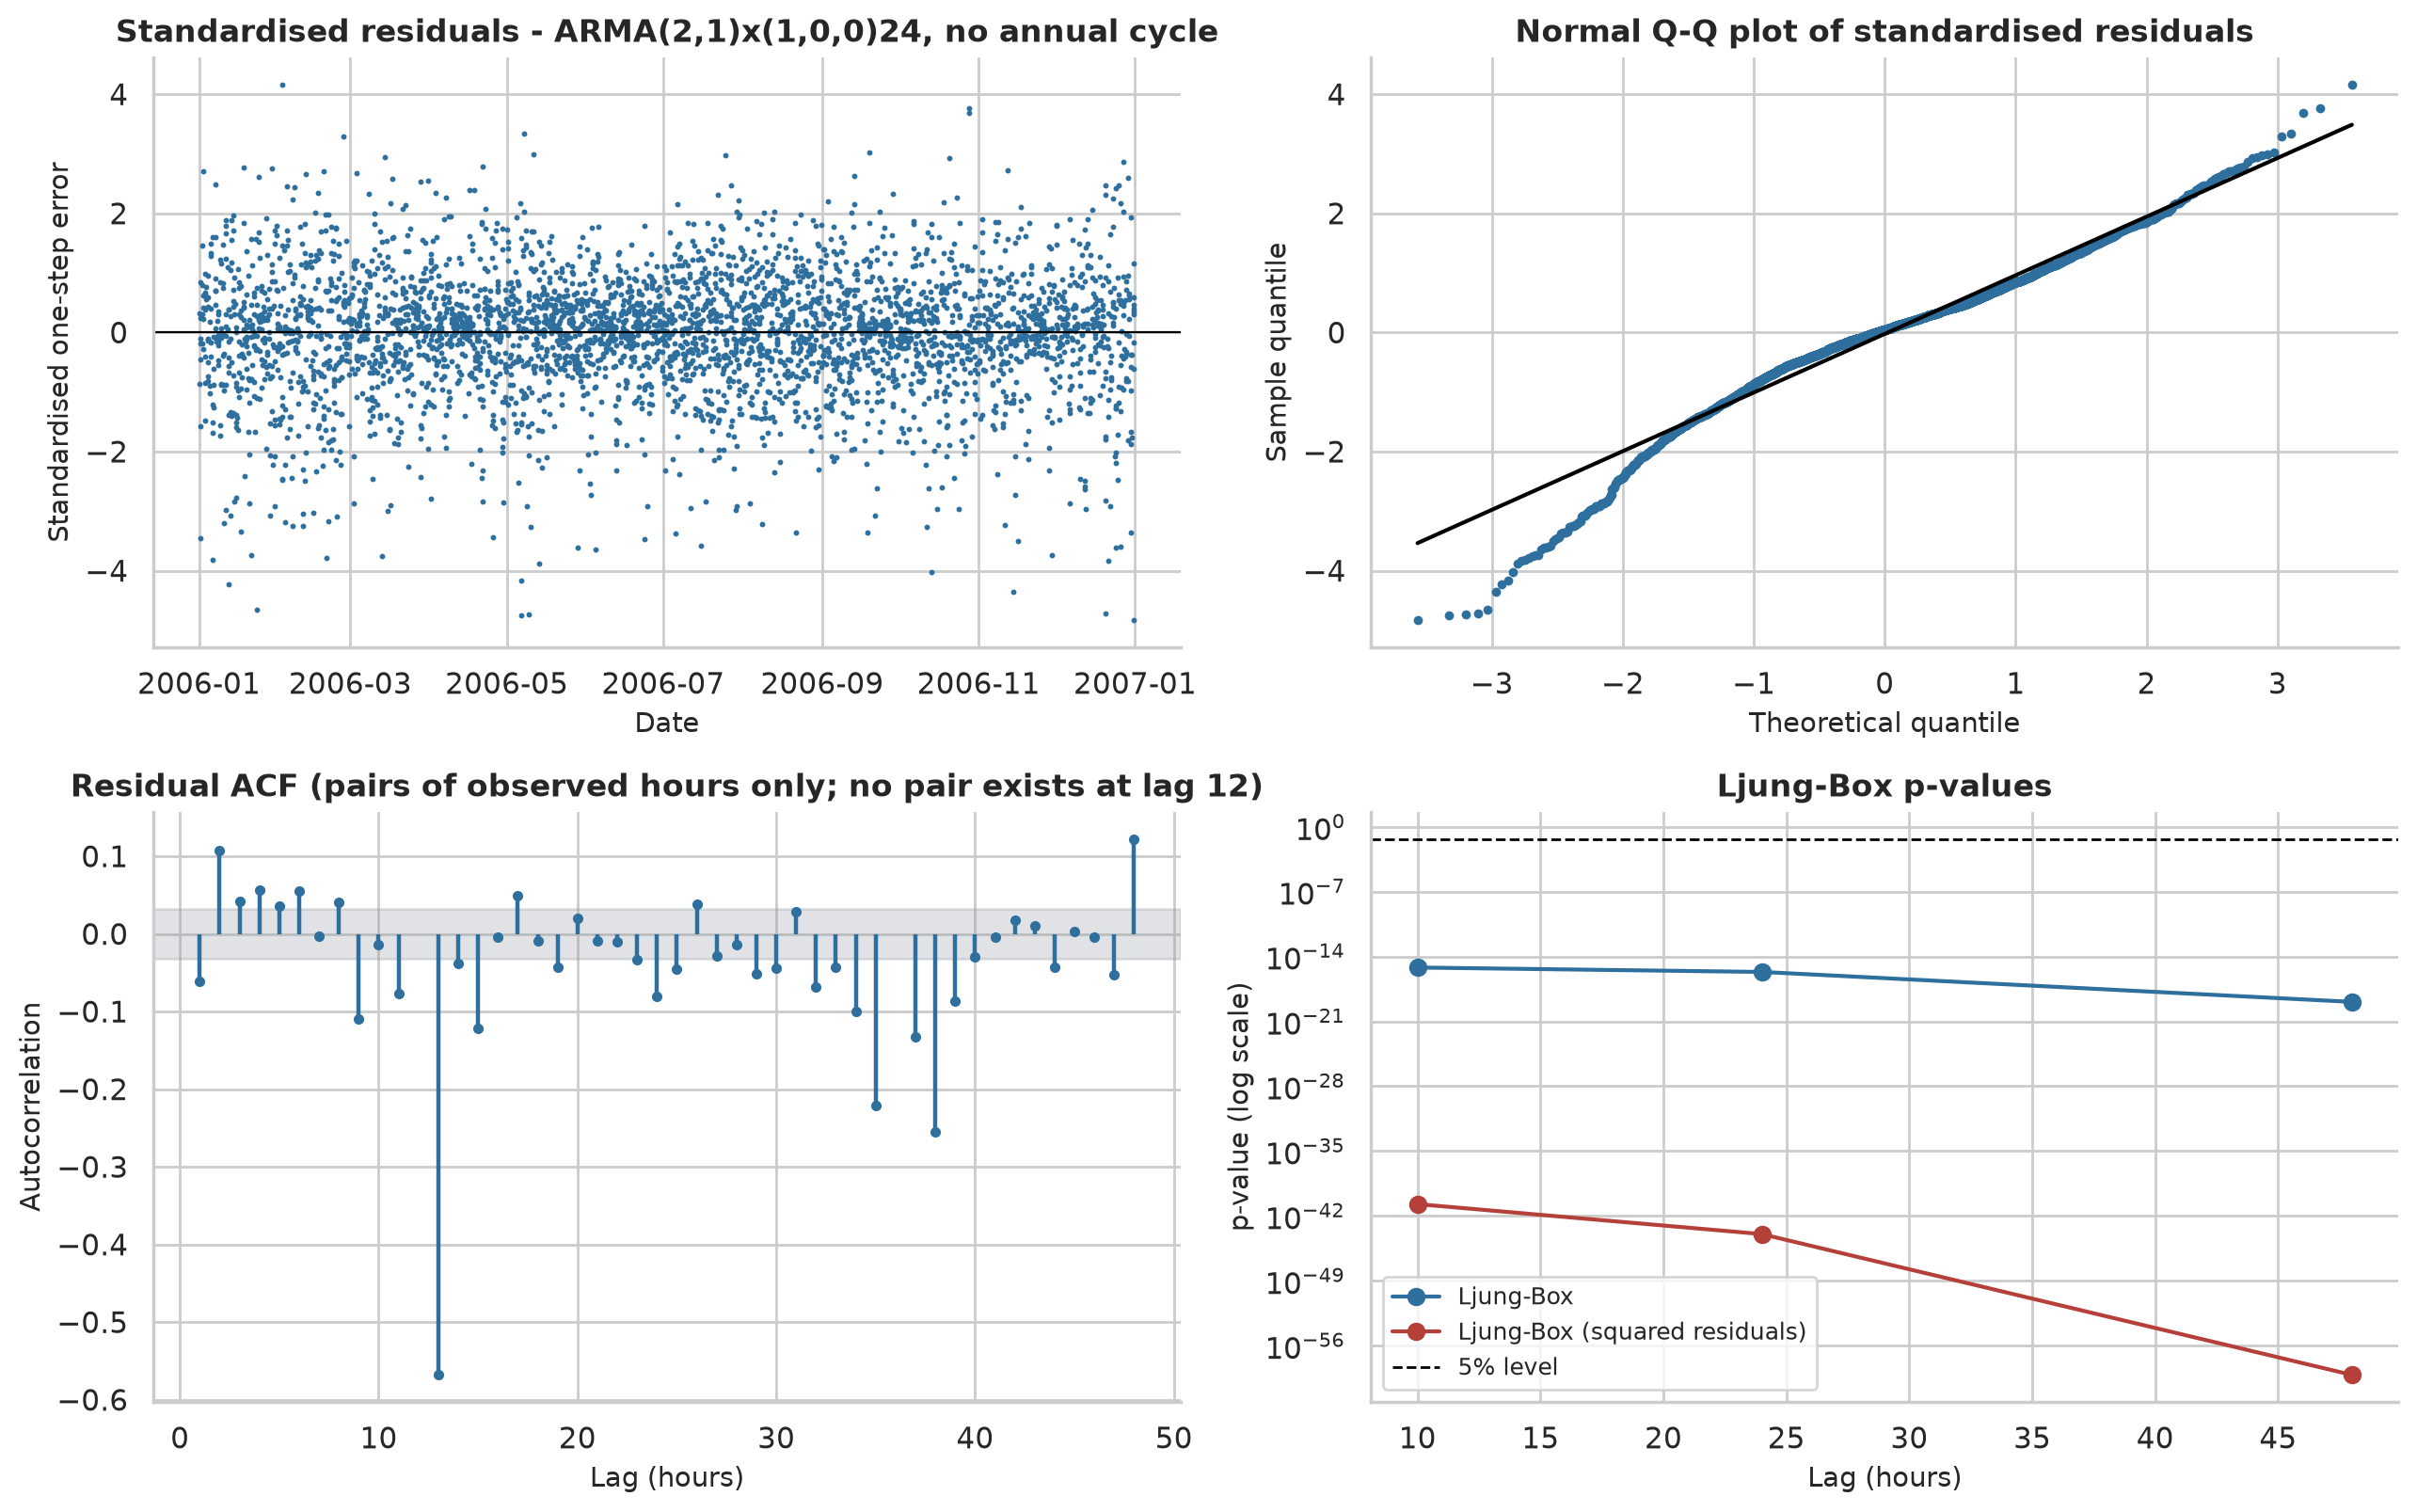

In [15]:
display(Image(str(config.FIG_DIR / 'fig12_arma_residual_diagnostics.png')))

In [16]:
d = pd.read_csv(config.RESULTS_DIR / 'diagnostic_results.csv')
d[d['family'] != 'i.i.d. distribution'].query("test in ['Ljung-Box','ARCH-LM']").head(30)

,model,test,lag,H0,statistic,p_value,reject_H0,n,family
3,iid Gaussian + annual cycle,Ljung-Box,10.0,no autocorrelation up to this lag,13546.2000,0.000000e+00,True,3846,ARMA
4,iid Gaussian + annual cycle,Ljung-Box,24.0,no autocorrelation up to this lag,14064.7000,0.000000e+00,True,3846,ARMA
5,iid Gaussian + annual cycle,Ljung-Box,48.0,no autocorrelation up to this lag,14297.4000,0.000000e+00,True,3846,ARMA
9,iid Gaussian + annual cycle,ARCH-LM,5.0,no conditional heteroskedasticity,2715.6200,0.000000e+00,True,3846,ARMA
10,iid Gaussian + annual cycle,ARCH-LM,12.0,no conditional heteroskedasticity,2718.9300,0.000000e+00,True,3846,ARMA
11,iid Gaussian + annual cycle,ARCH-LM,24.0,no conditional heteroskedasticity,2716.6700,0.000000e+00,True,3846,ARMA
15,AR(1),Ljung-Box,10.0,no autocorrelation up to this lag,389.8300,2.023940e-78,True,3846,ARMA
16,AR(1),Ljung-Box,24.0,no autocorrelation up to this lag,513.8290,4.663990e-94,True,3846,ARMA
17,AR(1),Ljung-Box,48.0,no autocorrelation up to this lag,645.5340,3.767480e-106,True,3846,ARMA
21,AR(1),ARCH-LM,5.0,no conditional heteroskedasticity,230.4910,8.395460e-48,True,3846,ARMA


## 7. Out-of-sample forecasting

In [17]:
pd.read_csv(config.RESULTS_DIR / 'forecast_scores.csv')

,method,n_test,MAE_index,RMSE_index,MAE_MW,RMSE_MW,RMSE_skill_vs_index_persistence
0,"Selected ARMA (ARMA(1,1)x(1,0,0)24)",758,0.038079,0.053244,93.985,127.711,0.133524
1,Persistence of index,758,0.045597,0.068425,105.508,147.392,0.000000
2,Training-mean index,758,0.235286,0.303500,631.540,842.490,-4.715980
3,Naive power persistence (P_{t-1}),758,NaN,NaN,452.593,569.864,-2.866320


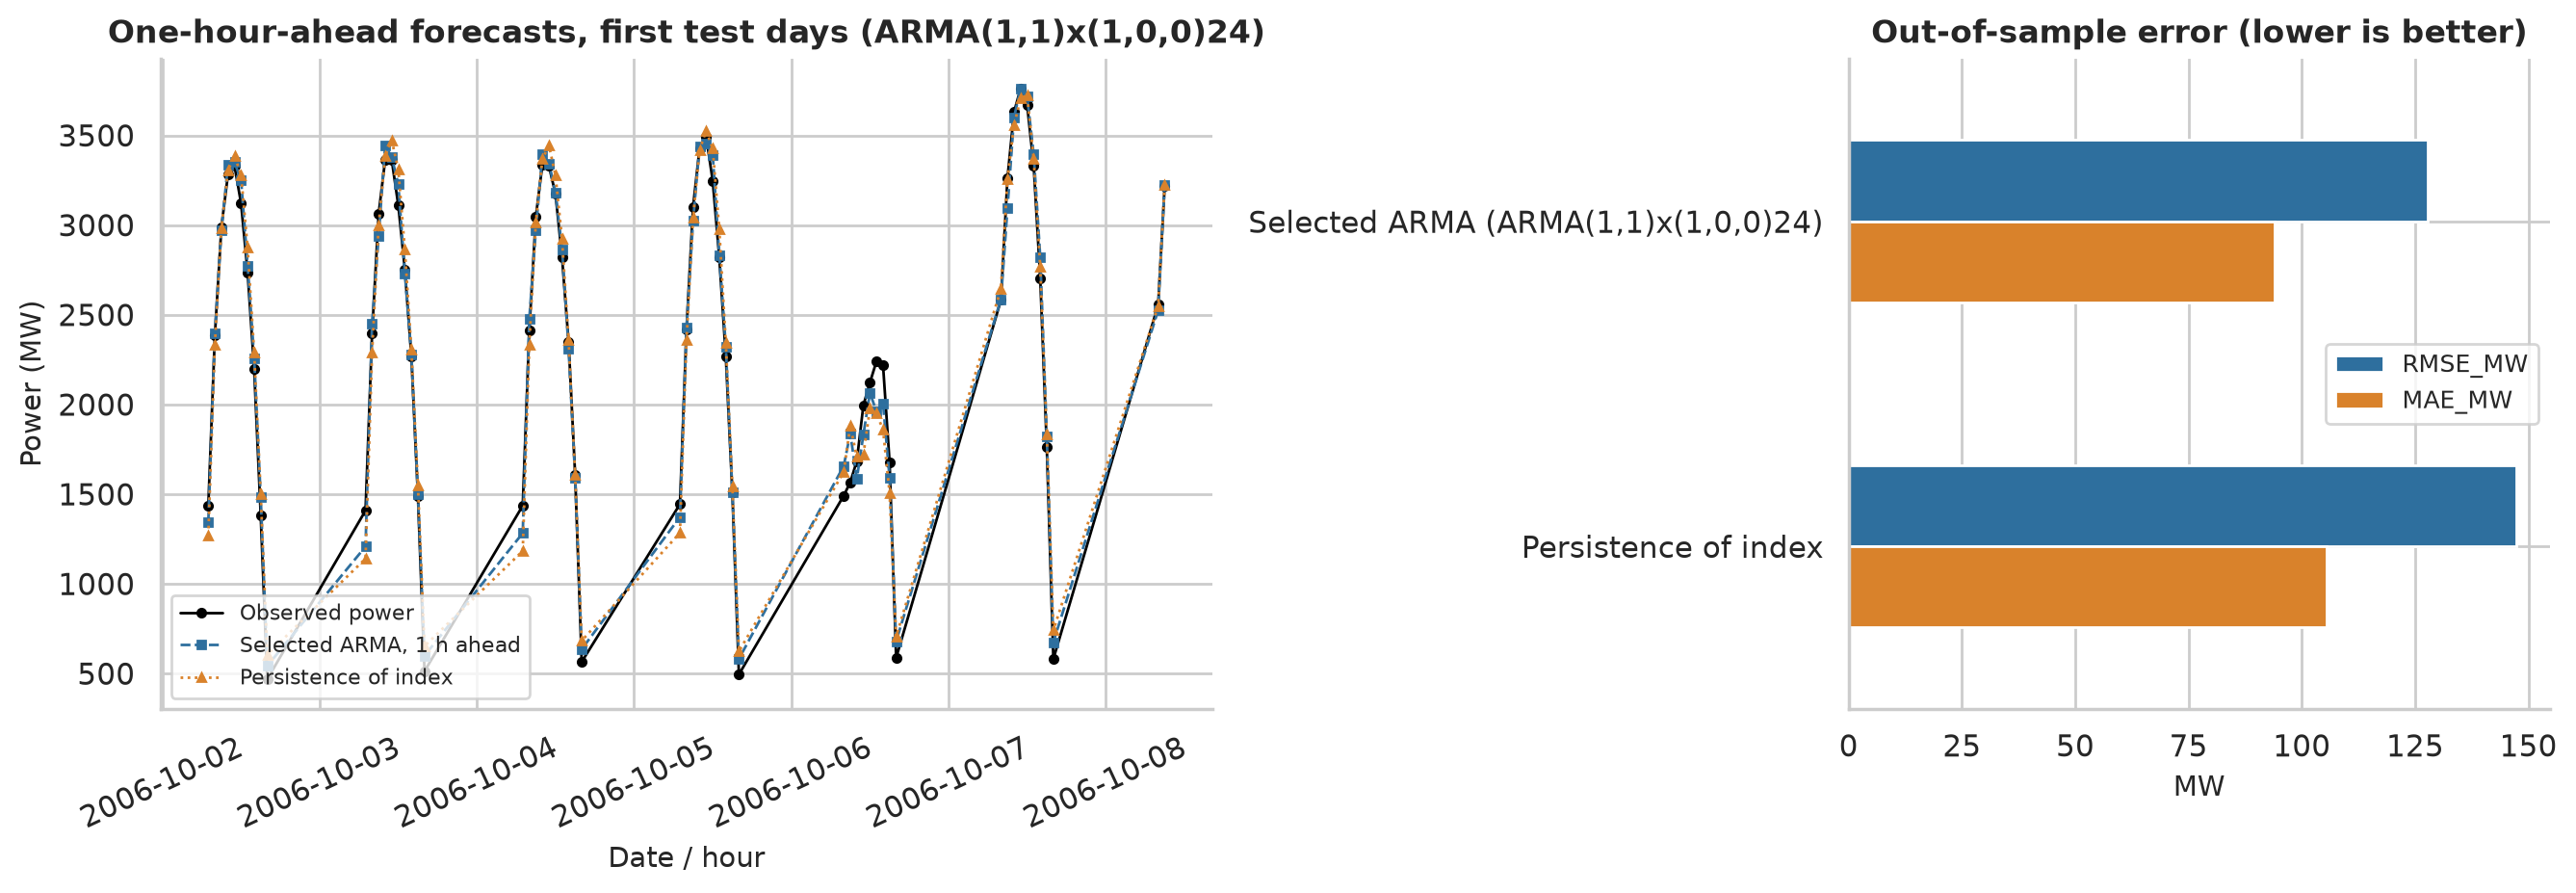

In [18]:
display(Image(str(config.FIG_DIR / 'fig14_forecast_evaluation.png')))